## 1. Математика

**Задача классификации**: по признакам $x = (x_1,\dots,x_d)$ выбрать класс $y$.

**Теорема Байеса** даёт **апостериорную** вероятность класса:

$$
P(y \mid x_1,\dots,x_d) = \frac{P(x_1,\dots,x_d \mid y)\,P(y)}{P(x_1,\dots,x_d)} \;\propto\; P(y)\,P(x_1,\dots,x_d \mid y)
$$

- $P(y)$ — **априорная** вероятность класса (доля класса в обучающей выборке);
- $P(x\mid y)$ — **правдоподобие**: как выглядят объекты этого класса. Насколько вероятны данные признаки для класса y;
- $P(x)$ вероятность встретить такой набор признаков в принципе. Одинаково для всех классов;

Проблема: оценить $P(x_1,\dots,x_d\mid y)$ в многомерном пространстве почти невозможно (нужно экспоненциально много данных).

**«Наивное» допущение** — признаки **условно независимы** при известном классе:

$$
P(x_1,\dots,x_d \mid y) = \prod_{j=1}^{d} P(x_j \mid y)
\quad\Longrightarrow\quad
\hat y = \arg\max_y \Big[ \log P(y) + \sum_{j=1}^{d} \log P(x_j \mid y) \Big]
$$

Теперь нужно оценить всего $d$ одномерных распределений на класс — это быстро и надёжно даже на малых данных.

### 1.1 Маленький пример: спам / не спам

In [45]:
from collections import Counter

docs   = ["buy cheap pills", "cheap pills now", "meeting tomorrow now", "project meeting notes"]
labels = ["spam", "spam", "ham", "ham"]
vocab  = sorted({w for d in docs for w in d.split()})

def word_prob(w, c, alpha): #
    cnt = Counter(
        word
        for d, l in zip(docs, labels)
        if l == c
        for word in d.split()
    )
    total = sum(cnt.values())
    return (cnt.get(w, 0) + alpha) / (total + alpha * len(vocab))

def posterior(text, alpha):
    joint = {}
    for c in ["spam", "ham"]:
        p = labels.count(c) / len(labels)
        for w in text.split():
            p *= word_prob(w, c, alpha)
        joint[c] = p
    z = sum(joint.values())
    return joint, ({c: v / z for c, v in joint.items()} if z > 0 else None)

query = "cheap pills meeting" 
for a in [1, 0]:
    joint, post = posterior(query, alpha=a)
    print(f"alpha={a}: P(y)*prod P(w|y) = {joint}  ->  posterior = {post}")

alpha=1: P(y)*prod P(w|y) = {'spam': 0.001639941690962099, 'ham': 0.0005466472303206996}  ->  posterior = {'spam': 0.75, 'ham': 0.25}
alpha=0: P(y)*prod P(w|y) = {'spam': 0.0, 'ham': 0.0}  ->  posterior = None


Что тут важно:

- При `alpha=1` (сглаживание Лапласа) всё считается: два «спамных» слова перевешивают одно «неспамное», спам получает бóльшую вероятность.
- При `alpha=0` слово `meeting` ни разу не встретилось в спаме, а `cheap` и `pills` — в не-спаме. Обе вероятности **обнуляются**, и решение принять нельзя. Это **проблема нулевой частоты**

In [46]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
cv = CountVectorizer(vocabulary=vocab)
mnb = MultinomialNB(alpha=1).fit(cv.transform(docs), labels)
print("sklearn  :", dict(zip(mnb.classes_, mnb.predict_proba(cv.transform([query]))[0].round(4))))

sklearn  : {np.str_('ham'): np.float64(0.25), np.str_('spam'): np.float64(0.75)}


## 2. Решающие границы: где NB хорош, где плох

Пять простых 2D-датасетов. Цвет фона — вероятность класса (синий ↔ красный), точки — **тестовая** выборка, в заголовке — accuracy на тесте.

Напоминание: граница GaussianNB — **квадратичная** (разные дисперсии у классов дают изогнутую границу), но эллипсы всегда ориентированы вдоль осей (нет ковариации между признаками). Отсюда ожидания:
- «два облака» — отлично;
- **сильно коррелированные признаки** — хуже (нарушена независимость);
- «круги» — вопреки интуиции, NB может справиться: у внутреннего и внешнего кругов разные дисперсии, а это как раз то, что ловит квадратичная граница (в отличие от линейной модели);
- XOR — взаимодействие признаков, которое NB в принципе не видит.

In [47]:
# 1. Для математики и массивов
import numpy as np

# 2. Для графиков
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Генераторы синтетических датасетов
from sklearn.datasets import make_blobs, make_moons, make_circles

# 4. Разделение данных на train/test
from sklearn.model_selection import train_test_split

# 5. Сами модели для сравнения
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# 6. Пайплайны и масштабирование (чтобы kNN и ЛогРег работали корректно)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 7. Утилита для отрисовки границ решений (появилась в sklearn 1.1)
from sklearn.inspection import DecisionBoundaryDisplay

In [48]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
RS = 42

# единые цвета
COL = {"Naive Bayes": "#E4572E", "Logistic Regression": "#2E86AB",
       "kNN": "#6A994E", "Decision Tree": "#8D6A9F"}

def make_models(nb=None):
    # Набор простых моделей для сравнения
    return {
        "Naive Bayes":         nb if nb is not None else GaussianNB(),
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "kNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=RS),
    }

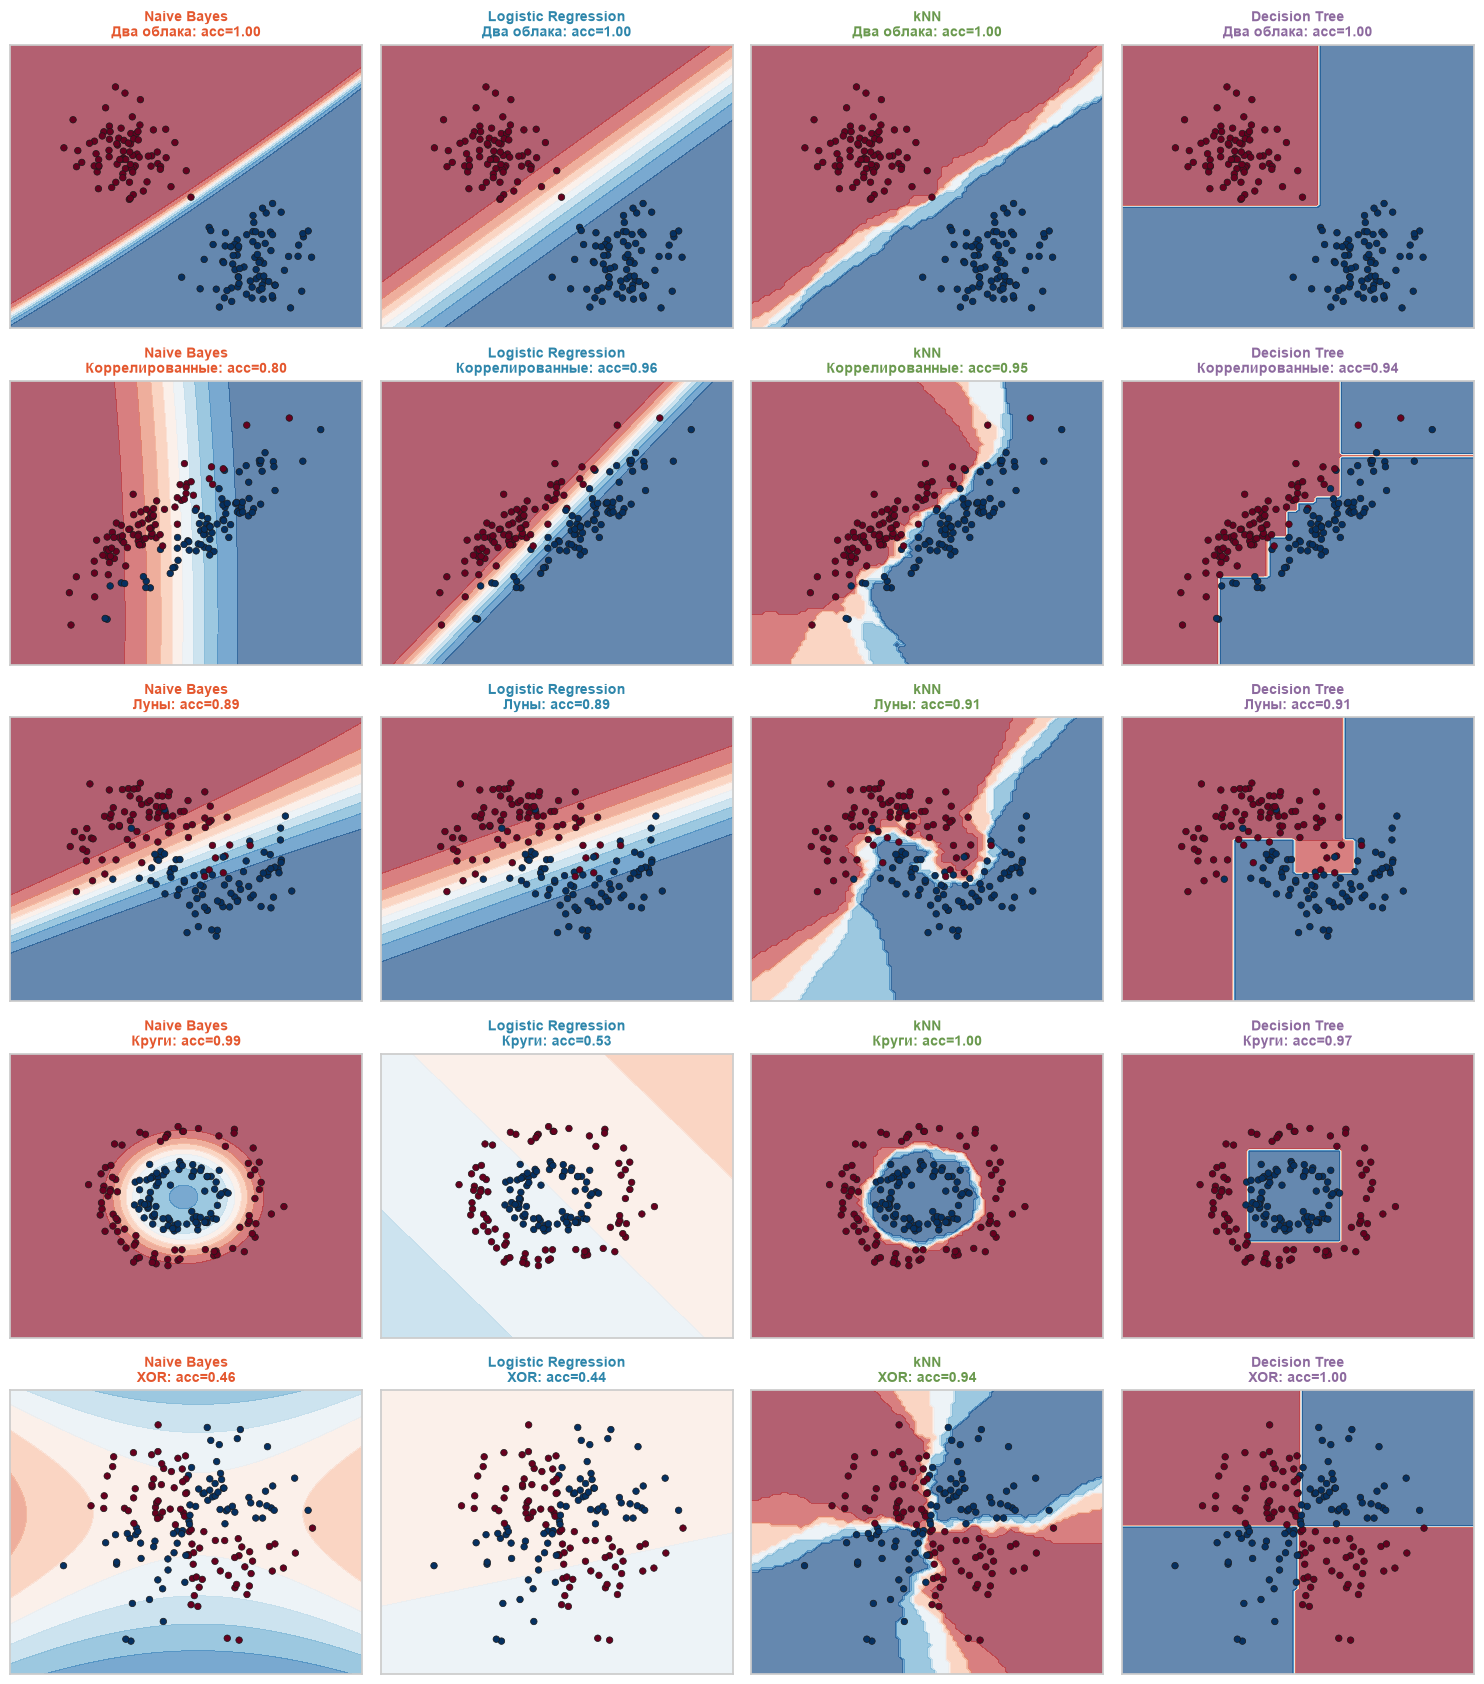

In [49]:
def make_datasets(n=400, seed=RS):
    rng = np.random.RandomState(seed)
    ds = {}
    ds["Два облака"] = make_blobs(n, centers=2, cluster_std=1.6, random_state=seed)
    # коррелированные признаки: общая ковариация с rho=0.9, классы сдвинуты по оси x
    cov = [[1, 0.9], [0.9, 1]]
    X = np.vstack([rng.multivariate_normal([0, 0], cov, n // 2),
                   rng.multivariate_normal([1.5, 0], cov, n // 2)])
    ds["Коррелированные"] = (X, np.r_[np.zeros(n // 2), np.ones(n // 2)].astype(int))
    ds["Луны"]  = make_moons(n, noise=0.25, random_state=seed)
    ds["Круги"] = make_circles(n, noise=0.1, factor=0.45, random_state=seed)
    Xx = rng.randn(n, 2) * 1.2
    ds["XOR"] = (Xx, (Xx[:, 0] * Xx[:, 1] > 0).astype(int))
    return ds

datasets = make_datasets()
fig, axes = plt.subplots(len(datasets), 4, figsize=(15, 3.4 * len(datasets)))
scores_2d = {}
for i, (dname, (X, y)) in enumerate(datasets.items()):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.4, random_state=RS, stratify=y)
    for j, (mname, model) in enumerate(make_models().items()):
        model.fit(Xtr, ytr)
        acc = model.score(Xte, yte)
        scores_2d[(dname, mname)] = acc
        ax = axes[i, j]
        DecisionBoundaryDisplay.from_estimator(model, X, response_method="predict_proba", ax=ax,
                                               cmap="RdBu", alpha=0.65, levels=np.linspace(0, 1, 11),
                                               xlabel="", ylabel="")
        ax.scatter(Xte[:, 0], Xte[:, 1], c=yte, cmap="RdBu", edgecolor="k", s=22, linewidth=0.5)
        ax.set_title(f"{mname}\n{dname}: acc={acc:.2f}", fontsize=10, color=COL[mname])
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Что видно на картинках**

- **Два облака:** все модели хороши, NB даёт плавную границу — это «идеальный случай» для него.
- **Коррелированные:** NB заметно проигрывает Logistic Regression: он «видит» два независимых признака и не понимает, что разделяющая информация спрятана в их *сочетании*.
- **Луны:** NB и Logistic Regression дают похожий результат, kNN и дерево чуть лучше — у них нет жёсткого допущения о форме классов.
- **Круги:** сюрприз — NB справляется почти идеально (≈0.99), а Logistic Regression проваливается (≈0.5): линейной границей концентрические классы не разделить, а у NB граница квадратичная. Но это «везение», связанное с тем, что классы различаются дисперсией вокруг общего центра.
- **XOR:** NB (≈0.46) и Logistic Regression — на уровне случайного угадывания; классы различаются *сочетанием* знаков двух признаков, а NB смотрит на признаки по отдельности. kNN и дерево справляются.
- **Фон NB очень «резкий»** (особенно на «двух облаках» и «коррелированных»): переходы от красного к синему происходят на узкой полосе. Это первый намёк на то, что вероятности NB слишком уверенные (раздел 4).

## 3. Главная слабость: нарушение независимости

### 3.1 Что на самом деле «выучил» GaussianNB на коррелированных данных

Эллипсы NB всегда **ось-ориентированы** (нет ковариации между признаками), а реальные классы — наклонённые.

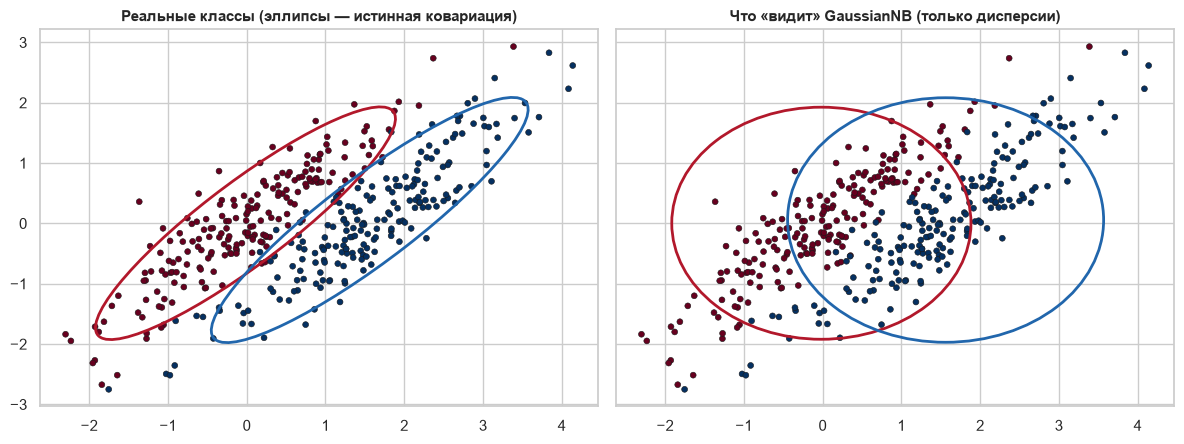

In [50]:
from matplotlib.patches import Ellipse

X, y = datasets["Коррелированные"]
nb = GaussianNB().fit(X, y)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, title in zip(axes, ["Реальные классы (эллипсы — истинная ковариация)", "Что «видит» GaussianNB (только дисперсии)"]):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu", edgecolor="k", s=18, linewidth=0.4)
    ax.set_title(title, fontsize=11)
for c, color in zip([0, 1], ["#B2182B", "#2166AC"]):
    Xc = X[y == c]
    # реальная ковариация — по собственным векторам
    w, V = np.linalg.eigh(np.cov(Xc.T))
    ang = np.degrees(np.arctan2(V[1, 1], V[0, 1]))
    axes[0].add_patch(Ellipse(Xc.mean(0), 2 * 2 * np.sqrt(w[1]), 2 * 2 * np.sqrt(w[0]), angle=ang,
                              fill=False, ec=color, lw=2))
    # эллипс NB: полуоси = 2*sigma по каждому признаку, без поворота
    sd = np.sqrt(nb.var_[c])
    axes[1].add_patch(Ellipse(nb.theta_[c], 2 * 2 * sd[0], 2 * 2 * sd[1], fill=False, ec=color, lw=2))
plt.tight_layout(); plt.show()

### 3.2 Эксперимент: Дублированные признаки

Сгенерируем данные, где признаки **действительно независимы внутри класса** — для них NB является *оптимальной* моделью. Затем **дублируем** столбцы: информации не прибавляется, но «наивный» NB считает копии независимыми свидетелями и учитывает один и тот же факт много раз.

- **(а)** дублируем *все* признаки $k$ раз → решение (знак логарифма отношения) почти не меняется, а вот логарифм-правдоподобие умножается на $k$ → **вероятности становятся экстремальными**;
- **(б)** дублируем *один слабый* признак $k$ раз → он «перекрикивает» остальные и **падает accuracy**.

Logistic Regression в обоих случаях подстраивает веса и почти не страдает.

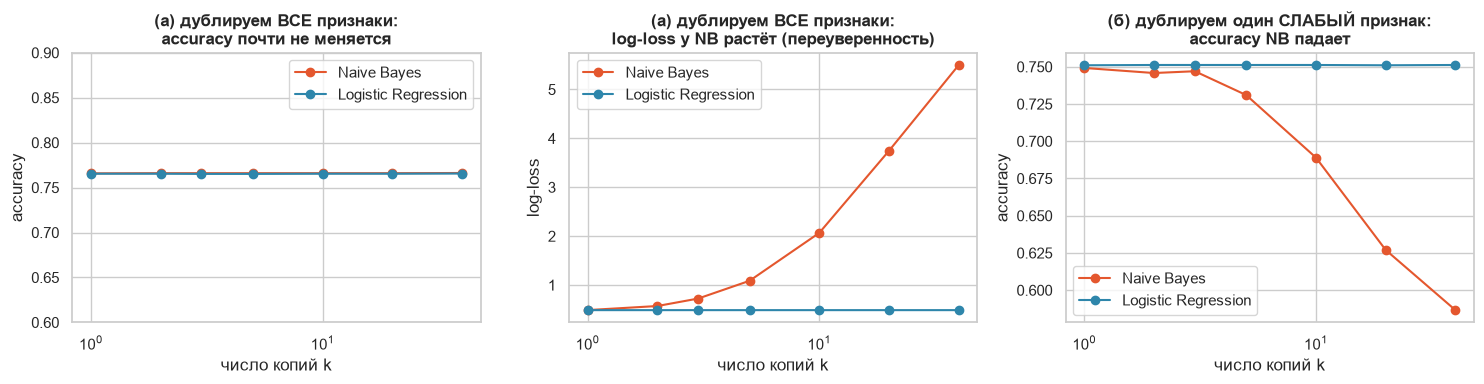

In [51]:
import pandas as pd

from sklearn.metrics import accuracy_score, log_loss

def gen_indep(n, mu, rng):
    # Бинарная задача: при известном классе признаки независимы N(±mu/2, 1)
    y = rng.randint(0, 2, n)
    X = rng.randn(n, len(mu)) + np.outer(y - 0.5, mu)
    return X, y

rng = np.random.RandomState(RS)
mu_a = np.full(6, 0.6)                      # (а) все признаки одинаково информативны
mu_b = np.array([0.2] + [0.6] * 5)          # (б) признак 0 — слабый
ks = [1, 2, 3, 5, 10, 20, 40]

def run_dup(mu, dup_all):
    Xtr, ytr = gen_indep(5000, mu, rng); Xte, yte = gen_indep(5000, mu, rng)
    rows = []
    for k in ks:
        f = (lambda X: np.tile(X, (1, k))) if dup_all else (lambda X: np.hstack([np.repeat(X[:, [0]], k, 1), X[:, 1:]]))
        for name in ["Naive Bayes", "Logistic Regression"]:
            m = make_models()[name].fit(f(Xtr), ytr)
            p = m.predict_proba(f(Xte))
            rows.append({"k": k, "model": name, "acc": accuracy_score(yte, p.argmax(1)),
                             "logloss": log_loss(yte, np.clip(p, 1e-15, 1 - 1e-15))})
    return pd.DataFrame(rows)

res_a = run_dup(mu_a, True); res_b = run_dup(mu_b, False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name in ["Naive Bayes", "Logistic Regression"]:
    a = res_a[res_a.model == name]; b = res_b[res_b.model == name]
    axes[0].plot(a.k, a.acc, "o-", color=COL[name], label=name)
    axes[1].plot(a.k, a.logloss, "o-", color=COL[name], label=name)
    axes[2].plot(b.k, b.acc, "o-", color=COL[name], label=name)
axes[0].set_title("(а) дублируем ВСЕ признаки:\naccuracy почти не меняется")
axes[1].set_title("(а) дублируем ВСЕ признаки:\nlog-loss у NB растёт (переуверенность)")
axes[2].set_title("(б) дублируем один СЛАБЫЙ признак:\naccuracy NB падает")
axes[0].set_ylabel("accuracy"); axes[1].set_ylabel("log-loss"); axes[2].set_ylabel("accuracy")
axes[0].set_ylim(0.6, 0.9)
for ax in axes: ax.set_xlabel("число копий k"); ax.set_xscale("log"); ax.legend()
plt.tight_layout(); plt.show()

**Вывод:** NB страдает от *коррелированных/избыточных* признаков двумя способами — теряется качество вероятностей (всегда) и может упасть accuracy (если «шумные» признаки повторяются много раз). Практические меры: убрать дубли и сильно коррелированные признаки, отобрать признаки, снизить размерность (PCA — но тогда признаки перестанут быть «естественными», например для счётчиков слов), или взять модель, которая корреляции учитывает (Logistic Regression, деревья).

## 4. Обманчивые вероятности NB

`predict_proba` у NB — плюс (есть вероятностный вывод «из коробки»), но **цифры не стоит принимать за настоящие вероятности**. Причина та же: независимость умножает вклады признаков, и модель получается переуверенной (чаще всего — вероятности жмутся к 0 и 1).

**Reliability diagram**: если модель откалибрована, то среди объектов с предсказанной вероятностью 0.8 ровно 80% должны оказаться положительными (точки лежат на диагонали). Возьмём данные из 3.2(а) с $k=3$ копиями признаков (при очень больших $k$ вероятности NB «насыщаются» в ровно 0 и 1, и информация об уверенности пропадает совсем).

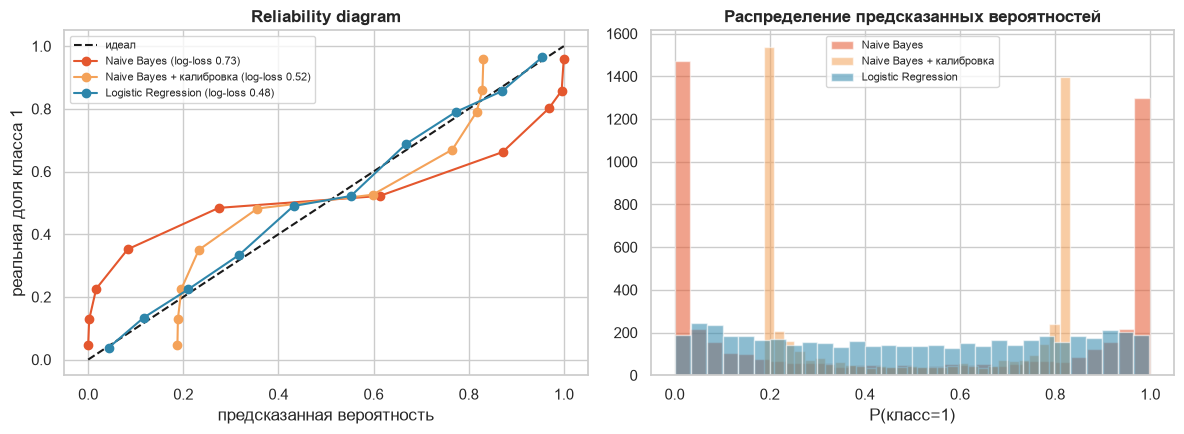

In [52]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

rng = np.random.RandomState(RS)
Xtr, ytr = gen_indep(500, mu_a, rng); Xte, yte = gen_indep(5000, mu_a, rng)
dup = lambda X: np.tile(X, (1, 3)) # k = 3
Xtr_d, Xte_d = dup(Xtr), dup(Xte)

cands = {
    "Naive Bayes":                 GaussianNB(),
    "Naive Bayes + калибровка":    CalibratedClassifierCV(GaussianNB(), method="sigmoid", cv=5), #sigmoid, isotonic
    "Logistic Regression":         make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
}
colors = {"Naive Bayes": COL["Naive Bayes"], "Naive Bayes + калибровка": "#F4A259", "Logistic Regression": COL["Logistic Regression"]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot([0, 1], [0, 1], "k--", label="идеал")
for name, m in cands.items():
    m.fit(Xtr_d, ytr)
    p = m.predict_proba(Xte_d)[:, 1]
    frac, mean_pred = calibration_curve(yte, p, n_bins=10, strategy="quantile")
    ll = log_loss(yte, np.clip(p, 1e-15, 1 - 1e-15))
    axes[0].plot(mean_pred, frac, "o-", color=colors[name], label=f"{name} (log-loss {ll:.2f})")
    axes[1].hist(p, bins=30, alpha=0.55, color=colors[name], label=name)
axes[0].set_xlabel("предсказанная вероятность"); axes[0].set_ylabel("реальная доля класса 1")
axes[0].set_title("Reliability diagram"); axes[0].legend(fontsize=8)
axes[1].set_title("Распределение предсказанных вероятностей"); axes[1].set_xlabel("P(класс=1)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Что делать:** если нужны именно вероятности (риски, пороги, ранжирование по уверенности) — **калибруйте** (`CalibratedClassifierCV`, sigmoid / isotonic) или используйте NB только для *ранжирования/решения*, а не для абсолютных чисел. Если нужен только класс — калибровка не обязательна: argmax часто остаётся верным даже при плохих вероятностях (см. 3.2 (а) — accuracy почти не меняется). Это известный парадокс: NB может быть хорошим *классификатором* и плохим *оценщиком вероятностей*.

## 5. Мало данных и скорость

### 5.1 Кривые обучения

Классический результат (Ng & Jordan, 2001): генеративная модель вроде NB достигает своего «потолка» **быстрее** при малом числе объектов, но дискриминативная (Logistic Regression) в пределе обычно **не хуже и чаще лучше**. Посмотрим, насколько это воспроизводится «на практике» (с современной LR из sklearn, у которой по умолчанию включена L2-регуляризация). Проверим на:

1. синтетике, где NB-допущение выполнено (30 независимых признаков);
2. реальных данных `breast_cancer` и `digits`.

Усредняем по повторам, тест — отдельная выборка.

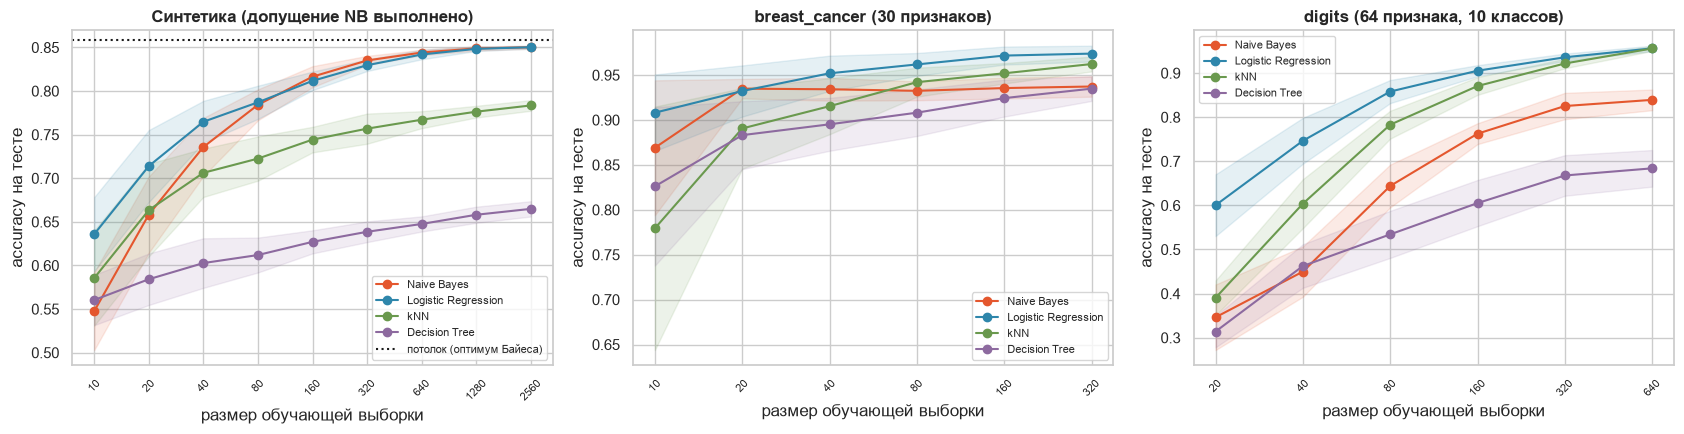

In [53]:
from scipy.stats import norm

from sklearn.datasets import (
    load_breast_cancer,
    load_digits,
)
def curve_synthetic(sizes, reps=20, d=30):
    rng = np.random.RandomState(RS)
    mu = rng.uniform(0.2, 0.6, d)
    Xte, yte = gen_indep(5000, mu, rng)
    out = {m: np.zeros((reps, len(sizes))) for m in COL}
    for r in range(reps):
        for si, n in enumerate(sizes):
            Xtr, ytr = gen_indep(n, mu, rng)
            for name, mdl in make_models().items():
                out[name][r, si] = mdl.fit(Xtr, ytr).score(Xte, yte)
    return out, norm.cdf(np.linalg.norm(mu) / 2)       # (результаты, байесовский потолок)

def curve_real(X, y, sizes, reps=20):
    out = {m: np.full((reps, len(sizes)), np.nan) for m in COL}
    for r in range(reps):
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.4, random_state=r, stratify=y)
        for si, n in enumerate(sizes):
            if n > len(Xtr): continue
            for name, mdl in make_models().items():
                out[name][r, si] = mdl.fit(Xtr[:n], ytr[:n]).score(Xte, yte)
    return out

def plot_curve(ax, sizes, out, title, ceiling=None):
    for name, arr in out.items():
        m = np.nanmean(arr, 0); s = np.nanstd(arr, 0)
        ax.plot(sizes, m, "o-", color=COL[name], label=name)
        ax.fill_between(sizes, m - s, m + s, color=COL[name], alpha=0.12)
    if ceiling: ax.axhline(ceiling, color="k", ls=":", label="потолок (оптимум Байеса)")
    ax.set_xscale("log"); ax.set_xlabel("размер обучающей выборки"); ax.set_ylabel("accuracy на тесте")
    ax.set_xticks(sizes); ax.set_xticklabels(sizes, rotation=45, fontsize=8); ax.minorticks_off()
    ax.set_title(title); ax.legend(fontsize=8)

sizes_syn = [10, 20, 40, 80, 160, 320, 640, 1280, 2560]
out_syn, ceil = curve_synthetic(sizes_syn)
Xb, yb = load_breast_cancer(return_X_y=True)
Xd, yd = load_digits(return_X_y=True)
sizes_bc, sizes_dg = [10, 20, 40, 80, 160, 320], [20, 40, 80, 160, 320, 640]
out_bc = curve_real(Xb, yb, sizes_bc)
out_dg = curve_real(Xd, yd, sizes_dg)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_curve(axes[0], sizes_syn, out_syn, "Синтетика (допущение NB выполнено)", ceil)
plot_curve(axes[1], sizes_bc, out_bc, "breast_cancer (30 признаков)")
plot_curve(axes[2], sizes_dg, out_dg, "digits (64 признака, 10 классов)")
plt.tight_layout(); plt.show()

**Как читать (по фактическим результатам):**

- **Синтетика (допущение NB верно):** NB выходит на «потолок» вместе с Logistic Regression примерно к 300–600 объектам — потолок у обеих один, это оптимум Байеса. А вот на самых малых выборках (10–80) Logistic Regression с L2-регуляризацией оказывается даже *лучше* NB. То есть утверждение «NB лучше на малых данных» из статьи Ng & Jordan (они сравнивали с нерегуляризованной LR) на практике **не обязательно воспроизводится** — регуляризованная LR тоже хорошо работает на малых выборках.
- **kNN и дерево** заметно хуже на 30+ признаках: «проклятие размерности». Это и есть настоящее преимущество простых моделей вроде NB/LR в высокой размерности.
- **Реальные данные:** NB упирается в более низкий «потолок» (breast_cancer — около 0.93–0.94 против ≈0.97 у LR; digits — ≈0.83 против ≈0.96): из-за коррелирующих признаков.
- Где NB обычно сильнее на малых выборках — тексты (раздел 8.5): десятки тысяч признаков и всего сотни документов. Проверьте это на реальных данных 20 Newsgroups, когда запустите ноутбук с интернетом.

### 5.2 Скорость обучения и предсказания

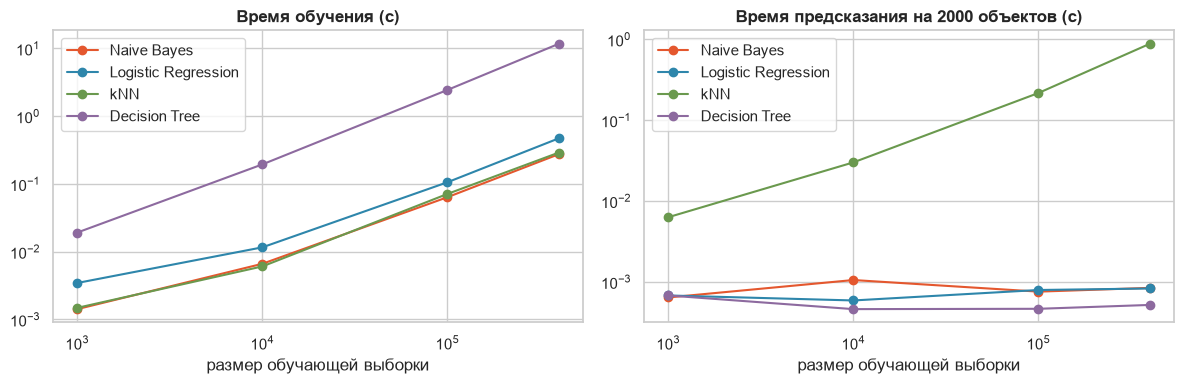

model,Decision Tree,Logistic Regression,Naive Bayes,kNN
n,,,,
1000,0.0192,0.0035,0.0014,0.0015
10000,0.1944,0.0116,0.0066,0.0061
100000,2.4415,0.1060,0.0638,0.0713
400000,11.7344,0.4719,0.2753,0.2906


In [54]:
import time

def timing(sizes, d=50, n_test=2000):
    rng = np.random.RandomState(RS)
    mu = rng.uniform(0.1, 0.4, d)
    Xte, _ = gen_indep(n_test, mu, rng)
    rows = []
    for n in sizes:
        Xtr, ytr = gen_indep(n, mu, rng)
        for name, mdl in make_models().items():
            t0 = time.perf_counter(); mdl.fit(Xtr, ytr); t_fit = time.perf_counter() - t0
            t0 = time.perf_counter(); mdl.predict(Xte);  t_pred = time.perf_counter() - t0
            rows.append(dict(n=n, model=name, fit=t_fit, predict=t_pred))
    return pd.DataFrame(rows)

tm = timing([1_000, 10_000, 100_000, 400_000])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in COL:
    t = tm[tm.model == name]
    axes[0].plot(t.n, t.fit, "o-", color=COL[name], label=name)
    axes[1].plot(t.n, t.predict, "o-", color=COL[name], label=name)
for ax, ttl in zip(axes, ["Время обучения (с)", "Время предсказания на 2000 объектов (с)"]):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("размер обучающей выборки"); ax.set_title(ttl); ax.legend()
plt.tight_layout(); plt.show()
tm.pivot(index="n", columns="model", values="fit").round(4)

NB обучается за один проход (время растёт линейно), а предсказание не зависит от размера обучающей выборки. **kNN** «не учится», но предсказание дорожает вместе с данными; Logistic Regression и дерево обучаются дольше. Именно поэтому NB — хороший *быстрый базовый уровень (baseline)*.

## 6. Реальные табличные данные: сводная таблица

Четыре классических датасета, 5-кратная стратифицированная кросс-валидация, **без подбора гиперпараметров** (сознательно: смотрим «из коробки»).

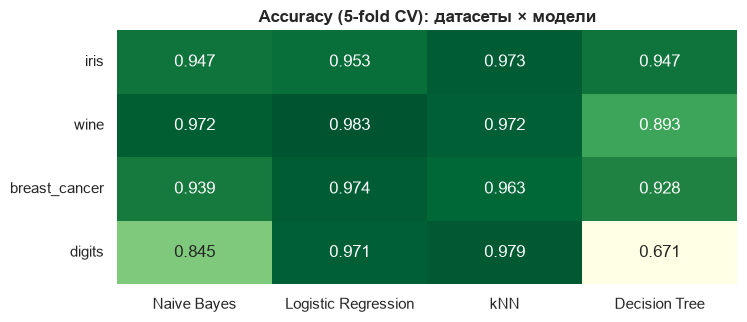

Время всей кросс-валидации, секунды:


,Naive Bayes,Logistic Regression,kNN,Decision Tree
iris,0.012,0.034,0.017,0.009
wine,0.009,0.033,0.018,0.011
breast_cancer,0.010,0.032,0.024,0.028
digits,0.017,0.112,0.026,0.057


In [55]:
from sklearn.datasets import (
    load_iris,
    load_wine,
)

from sklearn.model_selection import StratifiedKFold, cross_val_score
real = {"iris": load_iris(return_X_y=True), "wine": load_wine(return_X_y=True),
        "breast_cancer": load_breast_cancer(return_X_y=True), "digits": load_digits(return_X_y=True)}
cv5 = StratifiedKFold(5, shuffle=True, random_state=RS)

acc_rows, time_rows = {}, {}
for dname, (X, y) in real.items():
    acc_rows[dname], time_rows[dname] = {}, {}
    for mname, mdl in make_models().items():
        t0 = time.perf_counter()
        sc = cross_val_score(mdl, X, y, cv=cv5, scoring="accuracy")
        time_rows[dname][mname] = time.perf_counter() - t0
        acc_rows[dname][mname] = sc.mean()

acc = pd.DataFrame(acc_rows).T[list(COL)]
fig, ax = plt.subplots(figsize=(8, 3.3))
sns.heatmap(acc, annot=True, fmt=".3f", cmap="YlGn", vmin=0.7, vmax=1, cbar=False, ax=ax)
ax.set_title("Accuracy (5-fold CV): датасеты × модели"); ax.set_ylabel("")
plt.show()
print("Время всей кросс-валидации, секунды:"); pd.DataFrame(time_rows).T[list(COL)].round(3)

На «простых» данных (`iris`, `wine`) NB почти не отстаёт от остальных за долю времени. На `breast_cancer` (много сильно коррелирующих признаков) и особенно на `digits` (пиксели) отставание от Logistic Regression / kNN заметно: именно там, где нарушена независимость.

## 7. Нюанс: GaussianNB ожидает «колоколы»

Если признак сильно скошен (деньги, длительности, счётчики), нормальное распределение ему не подходит, и NB ошибается — даже если признаки независимы. Лечится **преобразованием признаков**: логарифм, `PowerTransformer` (Yeo-Johnson/Box-Cox), либо выбором другого распределения (`MultinomialNB` для счётчиков, дискретизация + `CategoricalNB`).

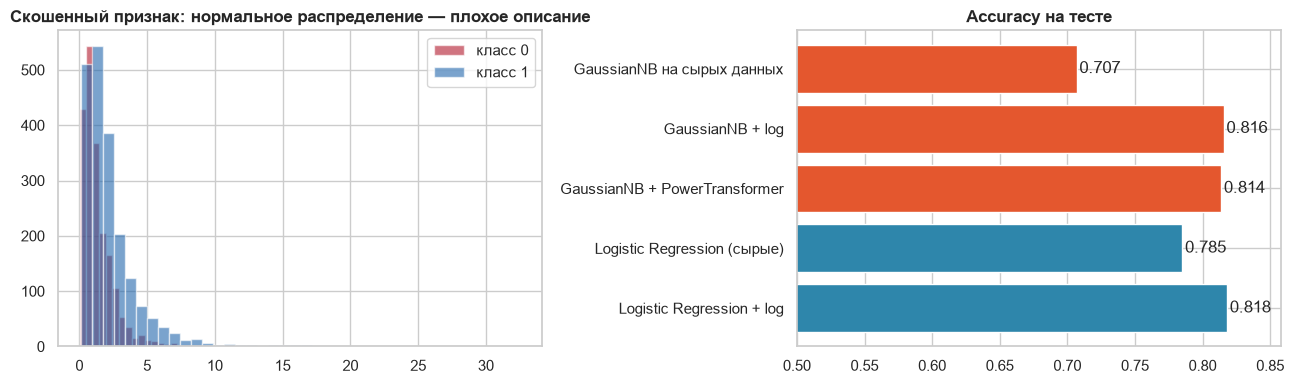

In [56]:
from sklearn.preprocessing import FunctionTransformer, PowerTransformer

rng = np.random.RandomState(RS)
n, d = 4000, 8
y = rng.randint(0, 2, n)
# лог-нормальные признаки: независимы, но сильно скошены
X = np.exp(rng.randn(n, d) * 0.8 + 0.5 * np.outer(y, np.ones(d)))
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.4, random_state=RS, stratify=y)

variants = {
    "GaussianNB на сырых данных":      GaussianNB(),
    "GaussianNB + log":                make_pipeline(FunctionTransformer(np.log), GaussianNB()),
    "GaussianNB + PowerTransformer":   make_pipeline(PowerTransformer(), GaussianNB()),
    "Logistic Regression (сырые)":     make_pipeline(StandardScaler(), LogisticRegression()),
    "Logistic Regression + log":       make_pipeline(__import__("sklearn.preprocessing", fromlist=["FunctionTransformer"]).FunctionTransformer(np.log), StandardScaler(), LogisticRegression()),
}
res = {k: v.fit(Xtr, ytr).score(Xte, yte) for k, v in variants.items()}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(X[y == 0, 0], bins=40, alpha=.6, label="класс 0", color="#B2182B")
axes[0].hist(X[y == 1, 0], bins=40, alpha=.6, label="класс 1", color="#2166AC")
axes[0].set_title("Скошенный признак: нормальное распределение — плохое описание"); axes[0].legend()
s = pd.Series(res)
bar_cols = [COL["Naive Bayes"] if "Gaussian" in k else COL["Logistic Regression"] for k in s.index]
axes[1].barh(s.index[::-1], s.values[::-1], color=bar_cols[::-1])
axes[1].set_xlim(0.5, s.max() + 0.04); axes[1].set_title("Accuracy на тесте")
for i, v in enumerate(s.values[::-1]): axes[1].text(v + 0.002, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.show()

**Вывод:** с сырыми скошенными признаками GaussianNB заметно хуже; простое логарифмирование (или `PowerTransformer`) возвращает ему качество, а модель NB с правильно подобранным распределением в этой задаче оптимальна. Logistic Regression на логарифмированных признаках получает то же самое, т.е. дело не в «магии NB», а в соответствии признаков допущениям модели.